BÀI 5 (Trang 26): Gom cụm MNIST bằng k-Means

Cell 0: Import thư viện

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import KMeans
from sklearn.metrics import (confusion_matrix, classification_report, accuracy_score,
                             adjusted_rand_score, normalized_mutual_info_score,
                             homogeneity_score, completeness_score, silhouette_score)
from scipy.optimize import linear_sum_assignment

from tensorflow.keras.datasets import mnist

Bước 1: Đọc và tiền xử lý dữ liệu MNIST

In [2]:
print("Lê Anh Pha - 6451071056")

(train_images, train_labels), (test_images, test_labels) = mnist.load_data()
print("train_images:", train_images.shape, "| train_labels:", train_labels.shape)

# Chuẩn hóa về [0,1] và làm phẳng 28x28 -> 784 chiều
X = train_images.reshape(len(train_images), -1) / 255.0
y_true = train_labels

print("Kích thước dữ liệu đưa vào k-Means:", X.shape)

Lê Anh Pha - 6451071056
11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
train_images: (60000, 28, 28) | train_labels: (60000,)
Kích thước dữ liệu đưa vào k-Means: (60000, 784)


Bước 2: Gom cụm bằng k-Means (k = 10)

In [3]:
print("Lê Anh Pha - 6451071056")

kmeans = KMeans(n_clusters=10, n_init=3, random_state=42)
clusters = kmeans.fit_predict(X)

print("Gom cụm xong.")
print("Số điểm trong mỗi cụm:", np.bincount(clusters))
print("Inertia:", kmeans.inertia_)

Lê Anh Pha - 6451071056
Gom cụm xong.
Số điểm trong mỗi cụm: [4534 5834 4578 8555 5855 5500 7326 4517 8933 4368]
Inertia: 2352952.6508345557


Bước 3: Hiển thị tâm của 10 cụm

Lê Anh Pha - 6451071056


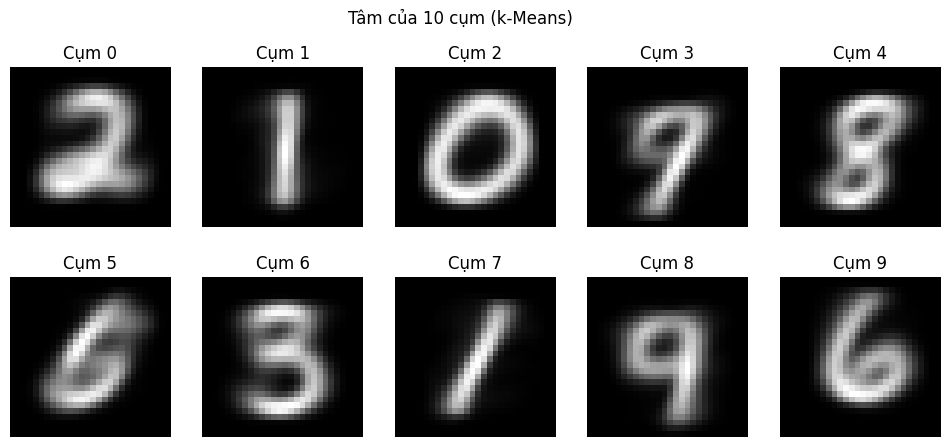

In [4]:
print("Lê Anh Pha - 6451071056")

fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for i, ax in enumerate(axes.ravel()):
    ax.imshow(kmeans.cluster_centers_[i].reshape(28, 28), cmap='gray')
    ax.set_title(f'Cụm {i}')
    ax.axis('off')
plt.suptitle('Tâm của 10 cụm (k-Means)')
plt.show()

Bước 4: Bảng đối chiếu cụm với nhãn thật

Lê Anh Pha - 6451071056
Nhãn thật     0     1     2     3     4     5     6     7     8     9
Cụm                                                                  
0             7     9  4157   173    29     5    53    40    44    17
1             2  3650   381   407   154   149   185   336   315   255
2          4308     0    44    22     7    54    53    20    29    41
3             5    10    68    36  1883   163     3  3774   165  2448
4            79     8   170   956    14  1009    16    15  3516    72
5          1087     6   210   431   211  1568  1693    10   261    23
6           232     6   276  3857     0  1807    34     5  1028    81
7             2  3042   330    49   208   233    39   256   273    85
8            45     6   190   171  3193   372    55  1805   178  2918
9           156     5   132    29   143    61  3787     4    42     9


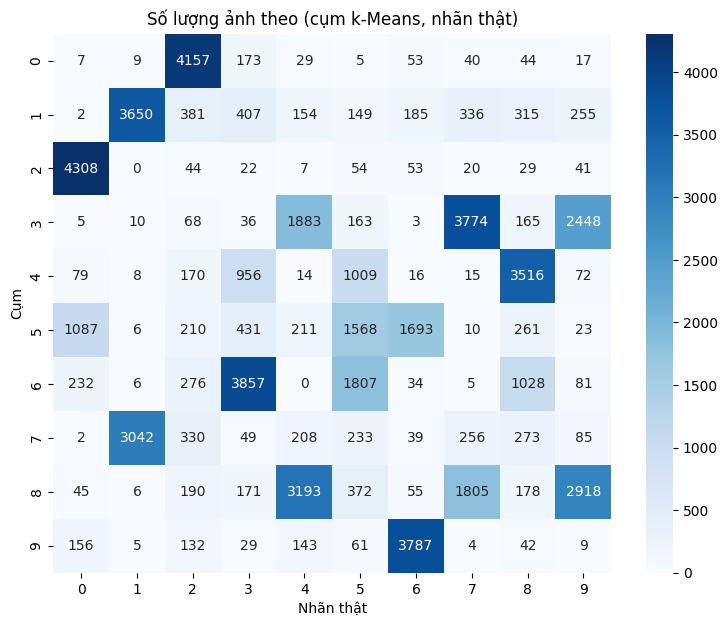

In [5]:
print("Lê Anh Pha - 6451071056")

bang = pd.crosstab(clusters, y_true, rownames=['Cụm'], colnames=['Nhãn thật'])
print(bang)

plt.figure(figsize=(9, 7))
sns.heatmap(bang, annot=True, fmt='d', cmap='Blues')
plt.title('Số lượng ảnh theo (cụm k-Means, nhãn thật)')
plt.show()

Bước 5: Ghép cụm với nhãn rồi đánh giá

Lê Anh Pha - 6451071056
Ghép cụm -> chữ số: {np.int64(0): np.int64(2), np.int64(1): np.int64(1), np.int64(2): np.int64(0), np.int64(3): np.int64(7), np.int64(4): np.int64(8), np.int64(5): np.int64(5), np.int64(6): np.int64(3), np.int64(7): np.int64(9), np.int64(8): np.int64(4), np.int64(9): np.int64(6)}

Accuracy sau khi ghép: 0.5316

Precision / Recall / F1-score từng chữ số:
              precision    recall  f1-score   support

           0     0.9410    0.7273    0.8205      5923
           1     0.6256    0.5414    0.5805      6742
           2     0.9169    0.6977    0.7924      5958
           3     0.5265    0.6291    0.5732      6131
           4     0.3574    0.5466    0.4322      5842
           5     0.2851    0.2892    0.2872      5421
           6     0.8670    0.6399    0.7363      5918
           7     0.4411    0.6024    0.5093      6265
           8     0.6005    0.6009    0.6007      5851
           9     0.0188    0.0143    0.0162      5949

    accuracy            

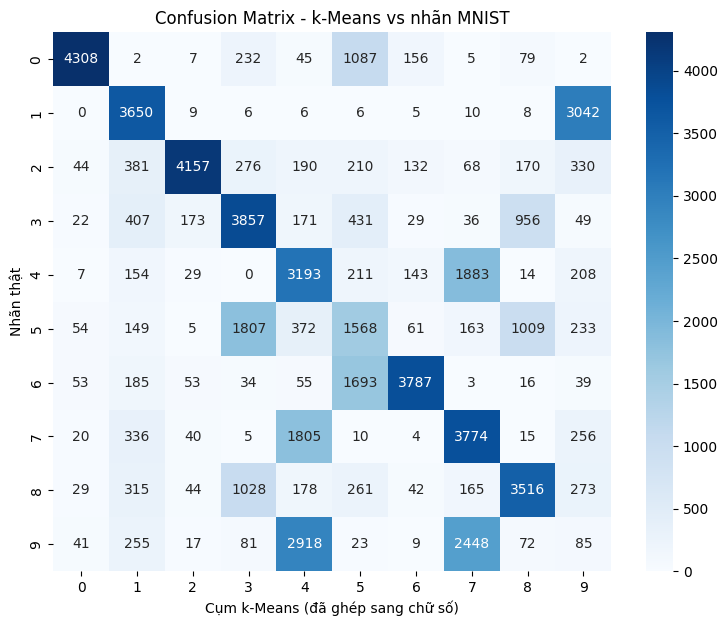

In [6]:
print("Lê Anh Pha - 6451071056")

cm_raw = confusion_matrix(clusters, y_true)          # hàng = cụm, cột = nhãn thật
row_ind, col_ind = linear_sum_assignment(-cm_raw)    # ghép 1-1 sao cho tổng khớp lớn nhất
mapping = dict(zip(row_ind, col_ind))
print("Ghép cụm -> chữ số:", mapping)

y_pred = np.array([mapping[c] for c in clusters])

print(f"\nAccuracy sau khi ghép: {accuracy_score(y_true, y_pred):.4f}")
print("\nPrecision / Recall / F1-score từng chữ số:")
print(classification_report(y_true, y_pred, digits=4))

cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(9, 7))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=range(10), yticklabels=range(10))
plt.xlabel('Cụm k-Means (đã ghép sang chữ số)')
plt.ylabel('Nhãn thật')
plt.title('Confusion Matrix - k-Means vs nhãn MNIST')
plt.show()

Bước 6: Các độ đo đánh giá gom cụm

In [7]:
print("Lê Anh Pha - 6451071056")

print(f"Adjusted Rand Index (ARI)  : {adjusted_rand_score(y_true, clusters):.4f}")
print(f"Normalized Mutual Info(NMI): {normalized_mutual_info_score(y_true, clusters):.4f}")
print(f"Homogeneity                : {homogeneity_score(y_true, clusters):.4f}")
print(f"Completeness               : {completeness_score(y_true, clusters):.4f}")

# Silhouette tính trên mẫu 10.000 ảnh cho nhanh (60.000 ảnh sẽ rất lâu)
sil = silhouette_score(X, clusters, sample_size=10000, random_state=42)
print(f"Silhouette (mẫu 10.000 ảnh): {sil:.4f}")

Lê Anh Pha - 6451071056
Adjusted Rand Index (ARI)  : 0.3634
Normalized Mutual Info(NMI): 0.4978
Homogeneity                : 0.4942
Completeness               : 0.5014
Silhouette (mẫu 10.000 ảnh): 0.0576
